Dimensiones de la base original: (53, 56)

Base limpia:
Modelo  Objetivo  Ventas_Reales
EMZOOM        22             14
  AION         2              5
 EMKOO         7             14
   GS4         3              5
   GN8         1              0
   GS8         9              3

Resultados de la regresión:
Intercepto: 3.0546
Pendiente: 0.5153
R²: 0.4746
Correlación: 0.6889

Ecuación: Ventas reales = 3.0546 + 0.5153 × Objetivo

Ventas observadas, estimadas y residuos:
Modelo  Objetivo  Ventas_Reales  Ventas_Estimadas  Residuo
EMZOOM        22             14           14.3908  -0.3908
  AION         2              5            4.0852   0.9148
 EMKOO         7             14            6.6616   7.3384
   GS4         3              5            4.6004   0.3996
   GN8         1              0            3.5699  -3.5699
   GS8         9              3            7.6921  -4.6921


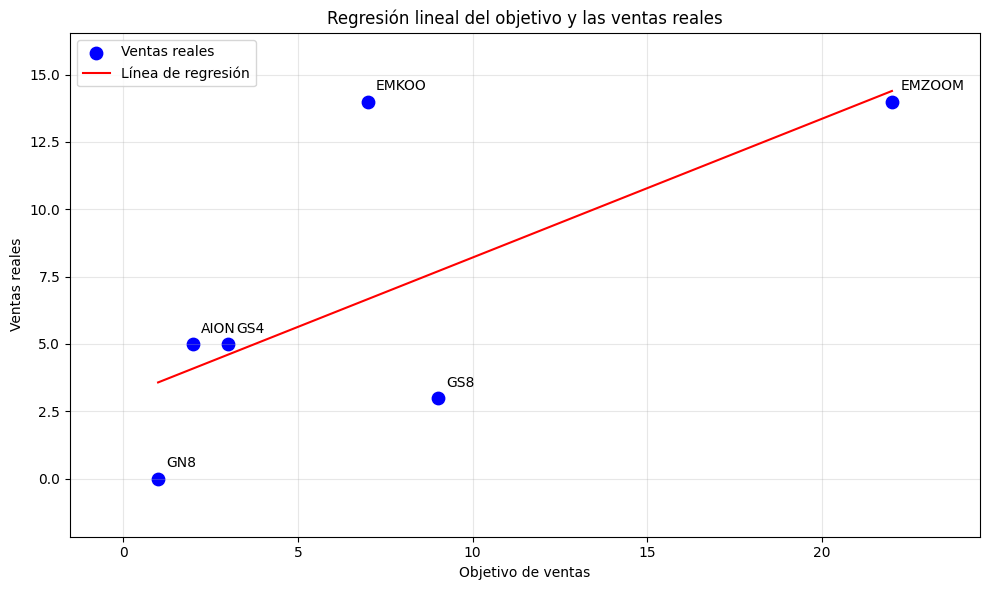

In [8]:
# 1. Importamos las librerías
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 2. Cargamos la base sin usar una fila como encabezado
archivo = "Analisis GAC Full7agosto 2026( BCS).csv"

df_raw = pd.read_csv(
    archivo,
    header=None,
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)

print("Dimensiones de la base original:", df_raw.shape)

# 3. Seleccionamos las columnas de modelo, objetivo y ventas reales
# Las posiciones comienzan en cero
df = df_raw.iloc[:, [1, 3, 4]].copy()

df.columns = [
    "Modelo",
    "Objetivo",
    "Ventas_Reales"
]

# 4. Limpiamos los nombres de los modelos
df["Modelo"] = (
    df["Modelo"]
    .str.replace("\u00a0", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.upper()
)

# 5. Conservamos los seis modelos de la imagen
modelos_analizados = [
    "EMZOOM",
    "AION",
    "EMKOO",
    "GS4",
    "GN8",
    "GS8"
]

df = df[
    df["Modelo"].isin(modelos_analizados)
].copy()

# 6. Limpiamos y convertimos las columnas numéricas
for columna in ["Objetivo", "Ventas_Reales"]:
    df[columna] = (
        df[columna]
        .str.replace("\u00a0", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    df[columna] = pd.to_numeric(
        df[columna],
        errors="coerce"
    )

# 7. Verificamos que cada modelo tenga un registro válido
# Conservamos las ventas de cero: sí son datos válidos
if (
    len(df) != len(modelos_analizados)
    or df["Modelo"].duplicated().any()
    or df[["Objetivo", "Ventas_Reales"]].isna().any().any()
):
    raise ValueError(
        "Revisa la base: debe existir un registro válido "
        "para cada uno de los seis modelos."
    )

df = df.reset_index(drop=True)

print("\nBase limpia:")
print(df.to_string(index=False))

# 8. Definimos las variables
# X: objetivo de ventas
# Y: ventas reales
X = df[["Objetivo"]]
y = df["Ventas_Reales"]

# 9. Creamos y ajustamos la regresión lineal simple
model = LinearRegression()
model.fit(X, y)

# 10. Calculamos las predicciones y los residuos
df["Ventas_Estimadas"] = model.predict(X)

df["Residuo"] = (
    df["Ventas_Reales"] - df["Ventas_Estimadas"]
)

# 11. Calculamos los indicadores
intercepto = model.intercept_
pendiente = model.coef_[0]
r_cuadrada = model.score(X, y)
correlacion = df["Objetivo"].corr(df["Ventas_Reales"])

print("\nResultados de la regresión:")
print(f"Intercepto: {intercepto:.4f}")
print(f"Pendiente: {pendiente:.4f}")
print(f"R²: {r_cuadrada:.4f}")
print(f"Correlación: {correlacion:.4f}")

print(
    f"\nEcuación: Ventas reales = {intercepto:.4f} "
    f"+ {pendiente:.4f} × Objetivo"
)

print("\nVentas observadas, estimadas y residuos:")
print(df.round(4).to_string(index=False))

# 12. Ordenamos los datos para dibujar la recta
df_grafica = df.sort_values("Objetivo")

# 13. Creamos la gráfica de la imagen
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Objetivo"],
    df["Ventas_Reales"],
    color="blue",
    s=80,
    label="Ventas reales"
)

plt.plot(
    df_grafica["Objetivo"],
    df_grafica["Ventas_Estimadas"],
    color="red",
    label="Línea de regresión"
)

# Agregamos los nombres de los modelos
for i in range(len(df)):
    plt.annotate(
        df.loc[i, "Modelo"],
        (
            df.loc[i, "Objetivo"],
            df.loc[i, "Ventas_Reales"]
        ),
        xytext=(6, 8),
        textcoords="offset points"
    )

plt.title("Regresión lineal del objetivo y las ventas reales")
plt.xlabel("Objetivo de ventas")
plt.ylabel("Ventas reales")
plt.margins(x=0.12, y=0.15)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()